In [1]:
import pandas as pd
import numpy as np

In [3]:
import os
import json
import pandas as pd

base_path = "../data/simulation/tree_diff_params"

rows = []

for seed in range(1000):
    path = os.path.join(base_path, f"T_{seed}", "params.json")

    try:
        with open(path, "r") as f:
            params = json.load(f)

        row = {"seed": seed}

        # Birth rates
        for k in ["A", "B", "C"]:
            row[f"birth_{k}"] = float(params.get("birth_rates", {}).get(k, None))

        # Death rates
        for k in ["A", "B", "C"]:
            row[f"death_{k}"] = float(params.get("death_rates", {}).get(k, None))

        # Transition probabilities
        for i in ["A", "B", "C"]:
            row_dict = params.get("transition_probabilities", {}).get(i, {})
            for j in ["A", "B", "C"]:
                row[f"Q_{i}_{j}"] = float(row_dict.get(j, None))

        rows.append(row)

    except (FileNotFoundError, json.JSONDecodeError, TypeError, ValueError) as e:
        print(f"Skipping seed {seed}: {e}")
        continue

df = pd.DataFrame(rows)


Skipping seed 17: float() argument must be a string or a real number, not 'NoneType'
Skipping seed 22: float() argument must be a string or a real number, not 'NoneType'
Skipping seed 27: float() argument must be a string or a real number, not 'NoneType'
Skipping seed 36: float() argument must be a string or a real number, not 'NoneType'
Skipping seed 59: float() argument must be a string or a real number, not 'NoneType'
Skipping seed 61: float() argument must be a string or a real number, not 'NoneType'
Skipping seed 62: float() argument must be a string or a real number, not 'NoneType'
Skipping seed 67: float() argument must be a string or a real number, not 'NoneType'
Skipping seed 72: float() argument must be a string or a real number, not 'NoneType'
Skipping seed 74: float() argument must be a string or a real number, not 'NoneType'
Skipping seed 89: float() argument must be a string or a real number, not 'NoneType'
Skipping seed 95: float() argument must be a string or a real num

In [4]:
df

,seed,birth_A,birth_B,birth_C,death_A,death_B,death_C,Q_A_A,Q_A_B,Q_A_C,Q_B_A,Q_B_B,Q_B_C,Q_C_A,Q_C_B,Q_C_C
0,0,3.778241,630.741116,0.499314,1.139006e-27,6.306082e+02,8.735044e-06,0.0,1.456457e-42,1.000000,0.0,0.0,0.0,0.0,0.0,0.0
1,1,6.734539,2.367440,1.276556,2.926008e-01,4.488725e-02,1.215062e-07,0.0,3.070242e-01,0.692976,0.0,0.0,0.0,0.0,0.0,0.0
2,2,0.000016,3.015664,0.000017,4.198728e-06,2.252038e-01,3.980922e-06,0.0,3.211811e-06,0.999997,0.0,0.0,0.0,0.0,0.0,0.0
3,3,4.427926,3.089102,1.043830,1.772355e-65,6.565971e-31,9.488326e-08,0.0,4.090966e-01,0.590903,0.0,0.0,0.0,0.0,0.0,0.0
4,4,5.068813,1.877518,1.981637,2.296599e-06,1.183873e-05,1.980892e+00,0.0,1.544316e-01,0.845568,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
903,994,0.000016,3.015664,0.000017,4.198728e-06,2.252038e-01,3.980922e-06,0.0,3.211811e-06,0.999997,0.0,0.0,0.0,0.0,0.0,0.0
904,995,4.571388,3.585086,1.485726,1.245864e-05,1.996095e+00,1.484728e+00,0.0,2.934372e-01,0.706563,0.0,0.0,0.0,0.0,0.0,0.0
905,997,5.772505,1.517087,1.278674,1.733509e-03,1.517062e+00,2.334804e-07,0.0,2.394504e-01,0.760550,0.0,0.0,0.0,0.0,0.0,0.0
906,998,2.900439,7.929748,1.470921,4.660057e-11,7.180371e+00,1.470634e+00,0.0,6.284628e-13,1.000000,0.0,0.0,0.0,0.0,0.0,0.0


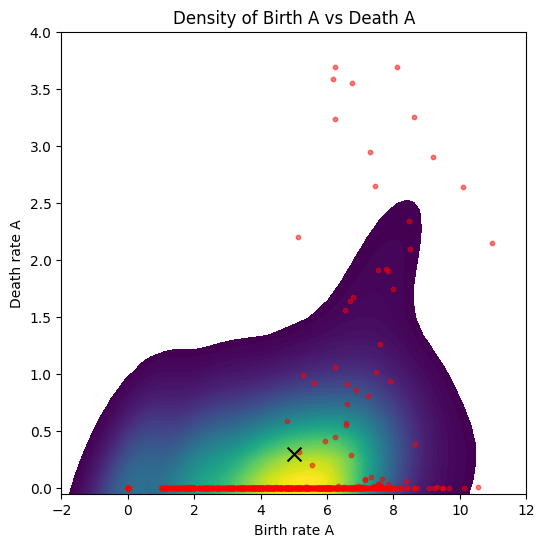

In [32]:
import matplotlib.pyplot as plt

import seaborn as sns

plt.figure(figsize=(6,6))
sns.kdeplot(
    x=df['birth_A'], 
    y=df['death_A'], 
    fill=True,       # colored density
    cmap='viridis',
    thresh=0.05,
    levels=100
)
plt.scatter(df['birth_A'], df['death_A'], s=10, c='red', alpha=0.5)
plt.scatter( 5, 0.3, marker="x", s=100, color='black')

plt.xlabel('Birth rate A')
plt.ylabel('Death rate A')
plt.xlim(-2, 12)
plt.ylim(-0.05, 4)
plt.title('Density of Birth A vs Death A')
plt.show()


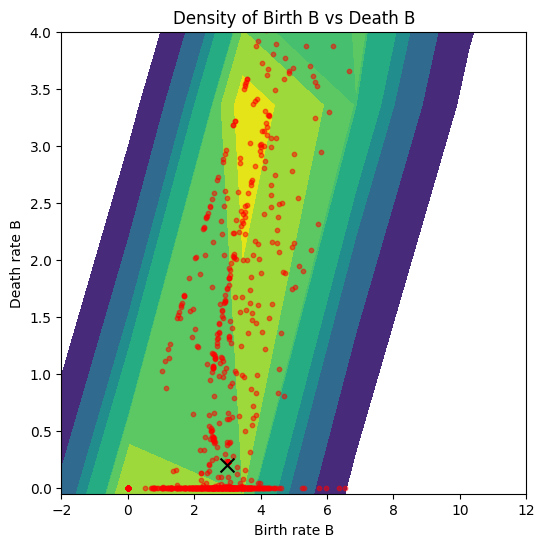

In [33]:
import matplotlib.pyplot as plt

import seaborn as sns

plt.figure(figsize=(6,6))
sns.kdeplot(
    x=df['birth_B'], 
    y=df['death_B'], 
    fill=True,       # colored density
    cmap='viridis',
    thresh=0.05,
    # levels=12
)
plt.scatter(df['birth_B'], df['death_B'], s=10, c='red', alpha=0.5)
plt.scatter( 3, 0.2, marker="x", s=100, color='black')
plt.xlabel('Birth rate B')
plt.ylabel('Death rate B')
plt.xlim(-2, 12)
plt.ylim(-0.05, 4)
plt.title('Density of Birth B vs Death B')
plt.show()


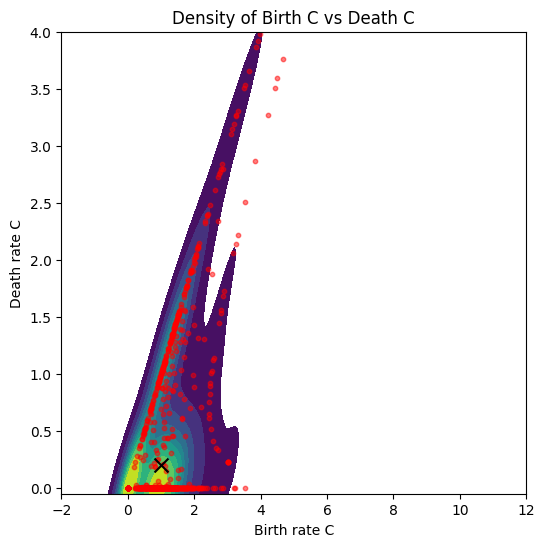

In [34]:
import matplotlib.pyplot as plt

import seaborn as sns

plt.figure(figsize=(6,6))
sns.kdeplot(
    x=df['birth_C'], 
    y=df['death_C'], 
    fill=True,       # colored density
    cmap='viridis',
    thresh=0.05,
    # levels=12
)
plt.scatter(df['birth_C'], df['death_C'], s=10, c='red', alpha=0.5)
plt.scatter( 1, 0.2, marker="x", s=100, color='black')

plt.xlabel('Birth rate C')
plt.ylabel('Death rate C')
plt.xlim(-2, 12)
plt.ylim(-0.05, 4)
plt.title('Density of Birth C vs Death C')
plt.show()
